# **MÓDULO 20 - Projeto de Credit Score - Naive Bayes**


No módulo 17 vocês realizaram a primeira etapa do projeto de crédito de vocês.
Então fizeram o tratamendo dos dados, balancearam as classes, transformaram as variáveis categóricas e separam base de treino e teste.
Nessa aula aplicaremos o algoritmo de naive bayes a base de vocês afim de tentarmos trazer previsões do score de crédito.

**IMPORTANTE:** Não se esqueçam de ao enviar o código de vocês para os tutores, enviarem as bases, pois como cada um de vocês realizou as alterações de tratamento indidualmente o tutor precisa ter acesso aos seus dados individuais.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score

Durante a aula nossa variável a ser prevista (churn) continha apenas 2 categorias, a base de vocês contém mais. O Naive Bayes pode ser aplicado para problemas de classificação com múltiplas classes da mesma forma que para problemas de classificação binária. O Naive Bayes é um algoritmo de classificação probabilístico que calcula a probabilidade de uma amostra pertencer a cada classe e seleciona a classe com a maior probabilidade como a previsão final.
Em resumo, o Naive Bayes pode ser aplicado da mesma maneira para problemas de classificação com múltiplas classes, e os mesmos princípios se aplicam em termos de treinamento, avaliação e aplicação do modelo.

# 1) Comece carregando as bases de treino (X e y) e teste (X e y).
Verifique se o número de linhas condiz, se as variáveis estão corretas sendo apenas a de score para y e as demais nas bases de X e por último, se Y está balanceada no teste.

In [2]:
# Ajuste os nomes dos arquivos se os seus forem diferentes.
# No Colab: envie as 4 bases pelo painel lateral (ícone de pasta) antes de executar.
ARQ_X_TREINO = "X_treino.csv"
ARQ_Y_TREINO = "y_treino.csv"
ARQ_X_TESTE  = "X_teste.csv"
ARQ_Y_TESTE  = "y_teste.csv"

# No M17 o score foi codificado em números: Low = 0, Average = 1, High = 2
NOMES_SCORE = {0: "Low (baixo)", 1: "Average (médio)", 2: "High (alto)"}

def ler(caminho):
    df = pd.read_csv(caminho)
    # remove colunas de índice exportadas sem querer (ex.: "Unnamed: 0")
    return df.loc[:, ~df.columns.str.startswith("Unnamed")]

X_treino, X_teste = ler(ARQ_X_TREINO), ler(ARQ_X_TESTE)
y_treino, y_teste = ler(ARQ_Y_TREINO), ler(ARQ_Y_TESTE)

# 1) Número de linhas
print("Formatos -> X_treino:", X_treino.shape, "| y_treino:", y_treino.shape)
print("Formatos -> X_teste :", X_teste.shape,  "| y_teste :", y_teste.shape)
print("Linhas de X e y iguais no treino?", len(X_treino) == len(y_treino))
print("Linhas de X e y iguais no teste? ", len(X_teste) == len(y_teste))

# 2) y só com o score e X com as demais variáveis
alvo = y_treino.columns[0]
print("\nColunas de y_treino:", list(y_treino.columns), "| y_teste:", list(y_teste.columns))
print(f"'{alvo}' aparece em X_treino?", alvo in X_treino.columns, "| em X_teste?", alvo in X_teste.columns)
print("X_treino e X_teste têm as mesmas colunas?", list(X_treino.columns) == list(X_teste.columns))
print("Colunas não numéricas em X:", list(X_treino.select_dtypes(exclude="number").columns))
print("Valores nulos em X_treino / X_teste:", X_treino.isna().sum().sum(), "/", X_teste.isna().sum().sum())

# y passa a ser uma Series (uma coluna só)
y_treino, y_teste = y_treino.iloc[:, 0], y_teste.iloc[:, 0]

# 3) Balanceamento das classes
print("\nDistribuição de y_treino (%):")
print((y_treino.value_counts(normalize=True).sort_index() * 100).round(2).rename(index=NOMES_SCORE))
print("\nDistribuição de y_teste (%):")
print((y_teste.value_counts(normalize=True).sort_index() * 100).round(2).rename(index=NOMES_SCORE))

Formatos -> X_treino: (270, 7) | y_treino: (270, 1)
Formatos -> X_teste : (33, 7) | y_teste : (33, 1)
Linhas de X e y iguais no treino? True
Linhas de X e y iguais no teste?  True

Colunas de y_treino: ['score_cod'] | y_teste: ['score_cod']
'score_cod' aparece em X_treino? False | em X_teste? False
X_treino e X_teste têm as mesmas colunas? True
Colunas não numéricas em X: []
Valores nulos em X_treino / X_teste: 0 / 0

Distribuição de y_treino (%):
score_cod
Low (baixo)        33.33
Average (médio)    33.33
High (alto)        33.33
Name: proportion, dtype: float64

Distribuição de y_teste (%):
score_cod
Low (baixo)         9.09
Average (médio)    21.21
High (alto)        69.70
Name: proportion, dtype: float64


# 2) Aplique o algoritmo de Naive Bayes aos dados de treinamento.

In [3]:
modelo = GaussianNB()
modelo.fit(X_treino, y_treino)

print("Modelo treinado.")
print("Classes aprendidas:", [NOMES_SCORE.get(c, str(c)) for c in modelo.classes_])
print("Número de variáveis usadas:", modelo.n_features_in_)

Modelo treinado.
Classes aprendidas: ['Low (baixo)', 'Average (médio)', 'High (alto)']
Número de variáveis usadas: 7


# 3) Faça a avaliação do modelo com os dados de treinamento.
Traga a acurácia, recall e plote a matriz de confusão. Não se esqueça de avaliar com suas palavras o desempenho do modelo, interpretando as métricas.

Dica: Para calcularmos o recall em classificação multi classe precisamos usar o atributo macro:
recall = recall_score(y_train, y_pred_train, average='macro')

Treino -> acurácia: 0.9926 | recall (macro): 0.9926


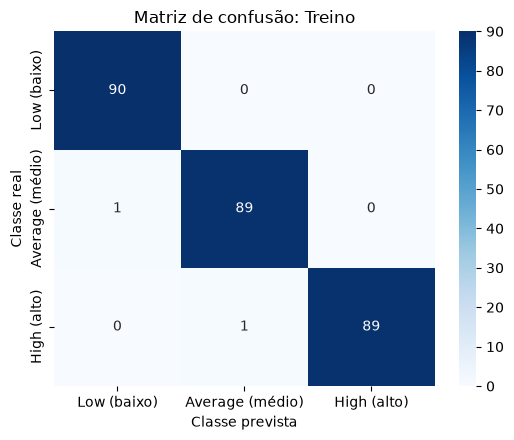

In [4]:
def avaliar(nome, X, y_real, modelo):
    """Calcula acurácia, recall macro e plota a matriz de confusão."""
    y_pred = modelo.predict(X)
    acc = accuracy_score(y_real, y_pred)
    rec = recall_score(y_real, y_pred, average="macro")
    cm = confusion_matrix(y_real, y_pred, labels=modelo.classes_)
    rotulos = [NOMES_SCORE.get(c, str(c)) for c in modelo.classes_]

    print(f"{nome} -> acurácia: {acc:.4f} | recall (macro): {rec:.4f}")

    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=rotulos, yticklabels=rotulos)
    plt.title(f"Matriz de confusão: {nome}")
    plt.xlabel("Classe prevista")
    plt.ylabel("Classe real")
    plt.tight_layout()
    plt.show()
    return acc, rec

acc_treino, rec_treino = avaliar("Treino", X_treino, y_treino, modelo)

**Interpretação do treino:**

O modelo acertou 268 dos 270 clientes do treino, ou seja, **99,26% de acurácia**. O recall macro deu o mesmo número porque as três classes têm 90 clientes cada, então a média entre elas não muda nada.

Na matriz de confusão vejo só dois erros: um cliente `Average` que o modelo achou que era `Low` e um `High` que ele achou que era `Average`. Ele nunca confundiu `Low` com `High`, o que é bom, porque são os dois extremos do score.

O desempenho é muito alto, mas não tiro conclusão só do treino: o modelo já viu esses dados (e vários deles foram repetidos pelo oversampling), então o treino sempre parece melhor do que a realidade. O que realmente conta é o teste.

# 4) Aplique o modelo aos dados de teste e realize a avaliação dos resultados, da mesma forma que fez acima. Não se esqueça de avaliar com as suas palavras e comparar o desempenho da base treino com a teste.

Teste -> acurácia: 0.9697 | recall (macro): 0.9524


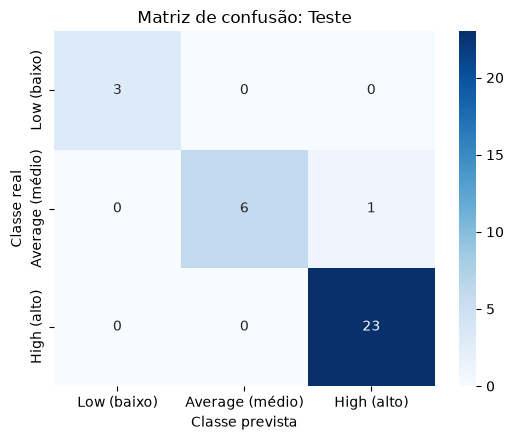


Comparação treino x teste:
                Treino   Teste  Diferença (treino - teste)
Acurácia        0.9926  0.9697                      0.0229
Recall (macro)  0.9926  0.9524                      0.0402


In [5]:
acc_teste, rec_teste = avaliar("Teste", X_teste, y_teste, modelo)

comparacao = pd.DataFrame(
    {"Treino": [acc_treino, rec_treino], "Teste": [acc_teste, rec_teste]},
    index=["Acurácia", "Recall (macro)"],
)
comparacao["Diferença (treino - teste)"] = comparacao["Treino"] - comparacao["Teste"]
print("\nComparação treino x teste:")
print(comparacao.round(4))

**Comparação treino x teste:**

No teste, o modelo acertou 32 dos 33 clientes: **96,97% de acurácia** e **95,24% de recall macro**. O único erro foi um cliente `Average` classificado como `High`. Os 3 `Low` e os 23 `High` foram todos acertados.

Comparando com o treino, a acurácia caiu cerca de 2,3 pontos e o recall macro cerca de 4 pontos. É uma queda pequena e os erros são do mesmo tipo (entre classes vizinhas), então, olhando só as métricas, não vejo sinal forte de overfitting. O recall macro caiu mais porque o erro foi na classe `Average`, que tem poucos clientes no teste mas pesa igual às outras na média.

Também foi importante olhar o recall macro e não só a acurácia: como cerca de 70% do teste é `High`, um modelo que chutasse sempre `High` acertaria quase 70%, e a acurácia sozinha enganaria.

**Ressalvas:** o teste é pequeno (33 clientes, só 3 `Low` e 7 `Average`), então um erro a mais ou a menos muda bastante os números. Mais importante: a checagem abaixo mostrou que **12 dos 33 clientes do teste (36%) têm uma cópia idêntica no treino**, por causa das 45 linhas duplicadas que mantive no M17. Para esses clientes o modelo já viu exatamente os mesmos dados, então o resultado do teste está **otimista** e a queda pequena entre treino e teste pode ser, em parte, efeito dos clientes repetidos. Por isso encaro os cerca de 97% com cautela: o modelo parece bom, mas a avaliação é menos confiável do que os números sugerem. Uma melhoria seria remover as duplicatas antes de separar treino e teste.

**Checagem sem as cópias:** para medir esse efeito, avaliei só os 21 clientes do teste que não têm cópia no treino. Nesse grupo a acurácia foi de **95,24%** (20 acertos em 21) e o recall macro de **91,67%**, um pouco abaixo do teste completo (96,97% e 95,24%). O único erro continua sendo o cliente `Average` previsto como `High`, e os 12 clientes com cópia foram todos acertados. Ou seja, as cópias ajudaram um pouco, mas o desempenho continua alto mesmo sem elas. Mesmo assim, esse grupo é minúsculo (16 `High`, 4 `Average` e só 1 `Low`), então o recall macro oscila muito e eu não tiro conclusões fortes dele.

**Checagem extra (opcional):** quantas linhas do teste têm uma cópia idêntica no treino?

In [6]:
# Linhas do teste cujas variáveis X são idênticas às de alguma linha do treino
treino_unico = X_treino.drop_duplicates()
copias = X_teste.merge(treino_unico, how="inner")

print(f"Linhas do teste com cópia idêntica no treino: {len(copias)} de {len(X_teste)} "
      f"({len(copias) / len(X_teste):.0%})")

Linhas do teste com cópia idêntica no treino: 12 de 33 (36%)


**Checagem extra 2 (opcional):** desempenho só nos clientes do teste que **não** têm cópia no treino. Com poucos clientes, interprete com cautela.

In [7]:
# Avaliação apenas nas linhas do teste sem cópia idêntica no treino
chave = list(X_teste.columns)
marca = X_teste.merge(treino_unico.assign(_copia=1), how="left", on=chave)["_copia"].fillna(0).astype(int).values
sem_copia = marca == 0

y_real_sc = y_teste[sem_copia]
y_pred_sc = modelo.predict(X_teste[sem_copia])
acc_sc = accuracy_score(y_real_sc, y_pred_sc)
rec_sc = recall_score(y_real_sc, y_pred_sc, average="macro")

print(f"Teste sem cópias no treino: {sem_copia.sum()} clientes")
print(f"Acurácia: {acc_sc:.4f} | Recall (macro): {rec_sc:.4f}")
print("\nClientes por classe nesse subconjunto:")
print(y_real_sc.map(NOMES_SCORE).value_counts())

Teste sem cópias no treino: 21 clientes
Acurácia: 0.9524 | Recall (macro): 0.9167

Clientes por classe nesse subconjunto:
score_cod
High (alto)        16
Average (médio)     4
Low (baixo)         1
Name: count, dtype: int64


# 5) Descreva com suas palavras o projeto desenvolvido nessa atividade e qual o nosso objetivo principal ao aplicarmos o algoritmo de naive bayes a base de crédito.
Utilize pelo menos 4 linhas.

Dica: Caso você ainda esteja tendo dificuldade em visualizar a aplicação dos projetos e objetivo, consulte seus tutores!

**Resposta 5:**

Neste projeto trabalhei com a base de crédito que tratei nos módulos anteriores: limpei os dados, transformei as variáveis categóricas, balanceei as classes e separei treino e teste. Agora o objetivo é prever o score de crédito de cada cliente, classificado em baixo, médio ou alto, a partir das demais variáveis da base.

Para isso apliquei o Naive Bayes, um algoritmo probabilístico que calcula a probabilidade de um cliente pertencer a cada classe de score e escolhe a classe com maior probabilidade. Ele assume que as variáveis são independentes entre si, o que simplifica o cálculo e o torna rápido e fácil de interpretar, e por isso é um bom ponto de partida para o problema.

Treinei o modelo na base de treino e avaliei com acurácia, recall macro e matriz de confusão. O recall macro é útil porque dá o mesmo peso às três classes, inclusive à de score baixo, que é a de maior risco para quem concede crédito. Comparar treino e teste mostra se o modelo realmente generaliza para clientes novos ou se apenas memorizou os dados que já viu.

Na prática, esse tipo de modelo apoia decisões como liberar ou não crédito e definir limites, ajudando a reduzir a inadimplência. Os resultados deste notebook servem de base para decidir se o Naive Bayes basta ou se vale testar algoritmos mais complexos nas próximas etapas.

# 6) Bônus: exemplos visuais interativos (React + Tailwind CSS)

Para visualizar os resultados do modelo de outra forma, execute a célula abaixo. Ela abre um painel interativo com três abas, todas alimentadas pelo **seu** modelo e pelos **seus** resultados:

- **Matriz de confusão:** alterna entre treino e teste e entre contagens e porcentagens; clique numa célula para ler o que ela significa e veja o recall de cada classe.
- **Treino × Teste:** compara acurácia e recall macro e mostra a linha do "chute" (sempre a classe mais frequente do teste).
- **Como o modelo decide:** mostra as curvas normais que o Naive Bayes aprendeu para cada classe e como a probabilidade muda conforme o valor de uma variável.

Requisitos: execute antes as células das questões 2, 3 e 4 (o painel usa `modelo`, `X_treino`, `y_treino`, `X_teste`, `y_teste`, `acc_treino`, `rec_treino`, `acc_teste` e `rec_teste`) e esteja conectado à internet, porque React e Tailwind são carregados de CDNs. Esta seção é um complemento e não substitui as respostas das questões 1 a 5.

In [8]:
#@title Visualização interativa (React + Tailwind CSS) { display-mode: "form" }
import json, html as _html
from IPython.display import HTML, display

_var = getattr(modelo, "var_", None)
if _var is None:                      # versões antigas do scikit-learn
    _var = modelo.sigma_

# Resultados reais do seu modelo, enviados ao painel
_DADOS = {
    "classes": [NOMES_SCORE.get(c, str(c)) for c in modelo.classes_],
    "cm_treino": confusion_matrix(y_treino, modelo.predict(X_treino), labels=modelo.classes_).tolist(),
    "cm_teste":  confusion_matrix(y_teste,  modelo.predict(X_teste),  labels=modelo.classes_).tolist(),
    "acc_treino": float(acc_treino), "rec_treino": float(rec_treino),
    "acc_teste":  float(acc_teste),  "rec_teste":  float(rec_teste),
    "baseline": float(y_teste.value_counts(normalize=True).max()),
    "features": list(X_treino.columns),
    "medias": modelo.theta_.tolist(),
    "variancias": _var.tolist(),
    "priors": modelo.class_prior_.tolist(),
    "minimos": X_treino.min().astype(float).tolist(),
    "maximos": X_treino.max().astype(float).tolist(),
}

_PAGE = r"""<!DOCTYPE html>
<html lang="pt-BR">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1, viewport-fit=cover">
<title>Naive Bayes: exemplos visuais</title>
<script src="https://cdn.tailwindcss.com/3.4.17"></script>
<script src="https://cdn.jsdelivr.net/npm/react@18.3.1/umd/react.production.min.js"></script>
<script src="https://cdn.jsdelivr.net/npm/react-dom@18.3.1/umd/react-dom.production.min.js"></script>
<style>
:root{--bg:#f6f7fb;--card:#ffffff;--fg:#14171f;--muted:#5b6475;--line:#d9deea;--accent:#2f5bea;--crit:#e5484d;--ok:#1f9d63;--warn:#d98a1c;
  box-sizing:border-box;padding-top:env(safe-area-inset-top,0px);padding-bottom:env(safe-area-inset-bottom,0px)}
@media (prefers-color-scheme: dark){:root:not([data-theme="light"]){--bg:#0f1219;--card:#181c26;--fg:#e9ecf4;--muted:#9aa3b5;--line:#2a3040;--accent:#7b96ff;--crit:#ff6b70;--ok:#3ecf8e;--warn:#e6b450}}
:root[data-theme="dark"]{--bg:#0f1219;--card:#181c26;--fg:#e9ecf4;--muted:#9aa3b5;--line:#2a3040;--accent:#7b96ff;--crit:#ff6b70;--ok:#3ecf8e;--warn:#e6b450}
html{scroll-padding-top:env(safe-area-inset-top,0px)}
body{margin:0;background:var(--bg);color:var(--fg);font-family:system-ui,-apple-system,"Segoe UI",Roboto,sans-serif}
.card{background:var(--card);border:1px solid var(--line);border-radius:14px}
.muted{color:var(--muted)}
.tab{border:1px solid var(--line);background:var(--card);color:var(--muted)}
.tab[aria-selected="true"]{background:var(--accent);border-color:var(--accent);color:#fff}
.num{font-variant-numeric:tabular-nums}
.cell{position:relative;border:1px solid var(--line);border-radius:10px;overflow:hidden;min-height:64px}
.cell[aria-pressed="true"]{outline:2px solid var(--fg)}
.fld{background:var(--card);color:var(--fg);border:1px solid var(--line);border-radius:8px}
</style>
</head>
<body>
<div id="root"></div>
<script>
const D = __DADOS__;
const { useState } = React;
const h = React.createElement;
const fmt = (x,d=2) => x.toFixed(d).replace('.',',');
const pct = (x,d=1) => fmt(x*100,d)+'%';
const CORES = ['var(--crit)','var(--warn)','var(--ok)'];
const npdf = (x,m,v) => Math.exp(-(x-m)*(x-m)/(2*v))/Math.sqrt(2*Math.PI*v);
const soma = a => a.reduce((s,v)=>s+v,0);

function Stat(p){
  return h('div',{className:'card p-3'},
    h('div',{className:'text-xs muted'},p.label),
    h('div',{className:'text-xl font-bold num'},p.value));
}

/* ---------- aba 1: matriz de confusão ---------- */
function Matriz(){
  const [q,setQ] = useState('teste');
  const [modo,setModo] = useState('abs');
  const [sel,setSel] = useState([0,0]);
  const cm = D['cm_'+q], K = cm.length, L = D.classes;
  const rs = cm.map(soma), tot = soma(rs);
  const ac = cm.reduce((a,r,i)=>a+r[i],0);
  const recs = cm.map((r,i)=>rs[i]?r[i]/rs[i]:0);
  const [i,j] = sel;
  const Seg = (val,cur,set,txt) => h('button',{className:'tab rounded-lg px-3 py-1.5 text-sm','aria-selected':cur===val,onClick:()=>set(val)},txt);
  const grade = h('div',{className:'grid gap-2 items-stretch',style:{gridTemplateColumns:`auto repeat(${K},minmax(0,1fr))`}},
    h('div'),
    L.map((n,c)=>h('div',{key:'h'+c,className:'text-xs muted text-center self-end'},'Previsto: '+n)),
    cm.map((r,a)=>[
      h('div',{key:'l'+a,className:'text-xs muted self-center pr-1',style:{maxWidth:90}},'Real: '+L[a]),
      r.map((v,b)=>{
        const sh = rs[a]?v/rs[a]:0, ok = a===b;
        const op = ok ? 0.1+0.9*sh : (v>0 ? 0.3+0.7*sh : 0.04);
        return h('button',{key:a+'-'+b,className:'cell','aria-pressed':a===i&&b===j,onClick:()=>setSel([a,b])},
          h('span',{className:'absolute inset-0',style:{background:ok?'var(--accent)':'var(--crit)',opacity:op}}),
          h('span',{className:'relative text-lg font-bold num',style:{color:(ok&&sh>0.5)?'#fff':'var(--fg)'}},modo==='abs'?v:pct(sh,0)));
      })
    ])
  );
  return h('div',{className:'grid gap-4 lg:grid-cols-5'},
    h('div',{className:'card p-4 grid gap-3 lg:col-span-3 content-start'},
      h('div',{className:'flex flex-wrap gap-2'},
        Seg('treino',q,setQ,'Treino'),Seg('teste',q,setQ,'Teste'),
        h('span',{className:'w-3'}),
        Seg('abs',modo,setModo,'Contagens'),Seg('pct',modo,setModo,'% da linha')),
      grade,
      h('p',{className:'text-sm'},
        h('b',null,cm[i][j]),' cliente(s) da classe real ',h('b',null,L[i]),' foram previstos como ',h('b',null,L[j]),
        i===j?' (acerto).':' (erro).')),
    h('div',{className:'lg:col-span-2 grid gap-3 content-start'},
      h('div',{className:'grid grid-cols-2 gap-3'},
        h(Stat,{label:'Acurácia',value:pct(ac/tot,2)}),
        h(Stat,{label:'Recall macro',value:pct(soma(recs)/K,2)})),
      h('div',{className:'card p-3 grid gap-2'},
        h('div',{className:'text-sm font-semibold'},'Recall por classe (acertos ÷ total real)'),
        recs.map((r,k)=>h('div',{key:k},
          h('div',{className:'flex justify-between text-xs'},h('span',null,L[k]),h('span',{className:'num muted'},cm[k][k]+' de '+rs[k]+' ('+pct(r)+')')),
          h('div',{style:{height:8,background:'var(--line)',borderRadius:4}},
            h('div',{style:{height:8,width:(r*100)+'%',background:CORES[k%3],borderRadius:4}}))))),
      h('p',{className:'text-xs muted'},'O recall macro é a média simples dos três recalls: cada classe pesa igual, mesmo a menor. Clique numa célula para ler o que ela significa.')));
}

/* ---------- aba 2: treino x teste ---------- */
function Comparacao(){
  const grupos = [['Acurácia',D.acc_treino,D.acc_teste],['Recall macro',D.rec_treino,D.rec_teste]];
  const W=640,H=280,L=44,R=20,T=24,B=44;
  const sy = v => H-B-v*(H-B-T);
  const gw = (W-L-R)/2;
  const nTeste = soma(D.cm_teste.map(soma));
  const barra = (v,x,cor,key) => h('g',{key},
    h('rect',{x:x,y:sy(v),width:64,height:sy(0)-sy(v),rx:4,style:{fill:cor}}),
    h('text',{x:x+32,y:sy(v)-6,textAnchor:'middle',fontSize:13,fontWeight:700,style:{fill:'var(--fg)'}},pct(v,1)));
  return h('div',{className:'grid gap-4'},
    h('div',{className:'card p-3'},
      h('svg',{viewBox:`0 0 ${W} ${H}`,className:'w-full',role:'img','aria-label':'Comparação de métricas entre treino e teste'},
        [0,0.25,0.5,0.75,1].map(t=>h('g',{key:t},
          h('line',{x1:L,x2:W-R,y1:sy(t),y2:sy(t),style:{stroke:'var(--line)'}}),
          h('text',{x:L-6,y:sy(t)+4,textAnchor:'end',fontSize:11,style:{fill:'var(--muted)'}},Math.round(t*100)+'%'))),
        grupos.map(([nome,a,b],g)=>h('g',{key:nome},
          barra(a,L+g*gw+gw/2-72,'var(--accent)','a'),
          barra(b,L+g*gw+gw/2+8,'var(--ok)','b'),
          h('text',{x:L+g*gw+gw/2,y:H-B+22,textAnchor:'middle',fontSize:13,style:{fill:'var(--fg)'}},nome))),
        h('line',{x1:L,x2:W-R,y1:sy(D.baseline),y2:sy(D.baseline),strokeDasharray:'6 4',strokeWidth:1.5,style:{stroke:'var(--crit)'}}),
        h('text',{x:W-R,y:sy(D.baseline)+15,textAnchor:'end',fontSize:11,style:{fill:'var(--crit)'}},'Chute: sempre a classe mais frequente do teste ('+pct(D.baseline,1)+')')),
      h('div',{className:'flex gap-4 text-xs muted px-1'},
        h('span',null,h('b',{style:{color:'var(--accent)'}},'■ '),'Treino'),
        h('span',null,h('b',{style:{color:'var(--ok)'}},'■ '),'Teste'))),
    h('div',{className:'grid grid-cols-2 sm:grid-cols-3 gap-3'},
      h(Stat,{label:'Queda na acurácia (treino − teste)',value:fmt((D.acc_treino-D.acc_teste)*100,1)+' p.p.'}),
      h(Stat,{label:'Queda no recall macro',value:fmt((D.rec_treino-D.rec_teste)*100,1)+' p.p.'}),
      h(Stat,{label:'Peso de 1 erro no teste',value:fmt(100/nTeste,1)+' p.p.'})),
    h('p',{className:'card p-3 text-sm'},
      'A linha tracejada mostra o que um “modelo” que chuta sempre a classe mais comum conseguiria no teste. Quanto mais acima dela, mais o modelo realmente aprendeu. Com apenas ',
      h('b',null,nTeste),' clientes no teste, um único erro move as métricas em cerca de ',h('b',null,fmt(100/nTeste,1)+' pontos'),', então diferenças pequenas entre treino e teste não são conclusivas.'));
}

/* ---------- aba 3: como o Naive Bayes decide ---------- */
function Bayes(){
  const ini = Math.max(0,D.features.indexOf('renda'));
  const [f,setF] = useState(ini);
  const [x,setX] = useState(null);
  const lo = D.minimos[f], hi = D.maximos[f], span = (hi-lo)||1;
  const xv = (x===null||x<lo||x>hi) ? (lo+hi)/2 : x;
  const K = D.classes.length;
  const ms = D.medias.map(r=>r[f]), vs = D.variancias.map(r=>Math.max(r[f],1e-9));
  const x0 = lo-0.15*span, x1 = hi+0.15*span;
  const N = 140, xs = Array.from({length:N+1},(_,t)=>x0+(x1-x0)*t/N);
  const ys = ms.map((m,k)=>xs.map(v=>npdf(v,m,vs[k])));
  const ymax = Math.max(...ys.map(a=>Math.max(...a)))*1.1;
  const bruto = ms.map((m,k)=>D.priors[k]*npdf(xv,m,vs[k]));
  const tot = soma(bruto)||1, post = bruto.map(v=>v/tot);
  const pred = post.indexOf(Math.max(...post));
  const W=640,H=250,L=20,R=20,T=14,B=34;
  const sx = v => L+(v-x0)/(x1-x0)*(W-L-R);
  const sy = v => H-B-v/ymax*(H-B-T);
  const trilha = k => ys[k].map((v,t)=>(t?'L':'M')+sx(xs[t])+','+sy(v)).join('');
  return h('div',{className:'grid gap-4 lg:grid-cols-5'},
    h('div',{className:'card p-4 grid gap-3 lg:col-span-2 content-start'},
      h('label',{className:'grid gap-1 text-sm'},
        h('span',{className:'muted'},'Variável analisada'),
        h('select',{className:'fld px-2 py-1.5',value:f,onChange:e=>{setF(parseInt(e.target.value));setX(null);}},
          D.features.map((n,t)=>h('option',{key:n,value:t},n)))),
      h('label',{className:'block'},
        h('div',{className:'flex justify-between text-sm'},h('span',{className:'muted'},'Valor do cliente'),h('span',{className:'font-semibold num'},fmt(xv,2))),
        h('input',{type:'range',className:'w-full',min:lo,max:hi,step:span/200,value:xv,style:{accentColor:'var(--accent)'},onChange:e=>setX(parseFloat(e.target.value))})),
      h('div',{className:'grid gap-2'},
        h('div',{className:'text-sm font-semibold'},'Probabilidade de cada classe'),
        post.map((p,k)=>h('div',{key:k},
          h('div',{className:'flex justify-between text-xs'},h('span',{className:k===pred?'font-bold':''},D.classes[k]+(k===pred?'  ← escolhida':'')),h('span',{className:'num muted'},pct(p))),
          h('div',{style:{height:8,background:'var(--line)',borderRadius:4}},
            h('div',{style:{height:8,width:(p*100)+'%',background:CORES[k%3],borderRadius:4}})))))),
    h('div',{className:'lg:col-span-3 grid gap-3 content-start'},
      h('div',{className:'card p-3'},
        h('svg',{viewBox:`0 0 ${W} ${H}`,className:'w-full',role:'img','aria-label':'Curvas gaussianas por classe'},
          D.classes.map((n,k)=>h('path',{key:k,d:trilha(k),fill:'none',strokeWidth:2.2,style:{stroke:CORES[k%3]}})),
          h('line',{x1:L,x2:W-R,y1:sy(0),y2:sy(0),style:{stroke:'var(--line)'}}),
          h('line',{x1:sx(xv),x2:sx(xv),y1:T,y2:sy(0),strokeWidth:2,strokeDasharray:'5 4',style:{stroke:'var(--accent)'}}),
          [x0,(x0+x1)/2,x1].map((v,t)=>h('text',{key:t,x:sx(v),y:H-10,textAnchor:t===0?'start':t===2?'end':'middle',fontSize:11,style:{fill:'var(--muted)'}},fmt(v,1)))),
        h('div',{className:'flex flex-wrap gap-x-4 text-xs muted px-1'},
          D.classes.map((n,k)=>h('span',{key:k},h('b',{style:{color:CORES[k%3]}},'━ '),n)))),
      h('p',{className:'card p-3 text-sm'},
        'Cada curva é a distribuição normal que o modelo aprendeu para a variável ',h('b',null,D.features[f]),' em cada classe (média e variância do treino). O Naive Bayes multiplica a probabilidade da classe pela altura da curva no valor do cliente e escolhe a classe de maior resultado. ',
        h('span',{className:'muted'},'O modelo real faz isso com todas as variáveis ao mesmo tempo, assumindo que elas são independentes (a parte “ingênua”). Aqui uso só uma, para você enxergar a ideia.'))));
}

/* ---------- app ---------- */
function App(){
  const [tab,setTab] = useState('m');
  const abas = [['m','Matriz de confusão'],['c','Treino × Teste'],['b','Como o modelo decide']];
  return h('main',{className:'max-w-5xl mx-auto px-4 py-5 grid gap-4'},
    h('header',null,
      h('h1',{className:'text-xl font-bold'},'Naive Bayes no score de crédito'),
      h('p',{className:'muted text-sm'},'Exemplos visuais com os resultados reais do seu notebook.')),
    h('div',{className:'flex gap-2 flex-wrap',role:'tablist'},
      abas.map(([k,t])=>h('button',{key:k,role:'tab',className:'tab rounded-lg px-3 py-2 text-sm font-medium','aria-selected':tab===k,onClick:()=>setTab(k)},t))),
    tab==='m'?h(Matriz):tab==='c'?h(Comparacao):h(Bayes));
}
ReactDOM.createRoot(document.getElementById('root')).render(h(App));
</script>
</body>
</html>
"""

_PAGE = _PAGE.replace("__DADOS__", json.dumps(_DADOS))

# O iframe isola o CSS do Tailwind e o React do restante do notebook
display(HTML(
    '<iframe srcdoc="' + _html.escape(_PAGE, quote=True) + '" '
    'width="100%" height="780" style="border:1px solid #cfd4e0;border-radius:10px"></iframe>'
))

C:\Users\eduar\AppData\Roaming\Python\Python313\site-packages\IPython\core\display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")
